# AI Workforce Intelligence, Phase 3: simulated paths and the standard forecast table (CS3216 Time Series Analysis and Forecasting)

Phase 3 refits each chosen model, draws 200 simulated future paths per series from the model's own backtest errors, checks those ranges on the holdout, and writes everything in one standard table.

> **Where this fits.** This is **Phase 3** of 6.
> **Needs:** `outputs/phase2/chosen_models.json` and `outputs/phase2/tables/cv_residuals.parquet` from Phase 2 (inside the zip).
> **Produces:** `outputs/phase3/forecasts/<series>.parquet` (the standard table), the scenario table and `inputs_for_phase4.json`, used by the Phase 4 cost and value engine.

> **How to use this notebook**
> 1. In Colab: *Runtime > Run all*. When asked, upload `ai-workforce-intel_colab.zip` (the same zip for all three notebooks).
> 2. `MODE = "show"` (default) only displays the finished results inside the zip: under 1 minute.
> 3. `MODE = "run"` recomputes **this phase only** (under 1 minute (both --fast and full) on Colab), using the earlier phases' results in the zip.
> 4. Outside Colab, put the unzipped `ai-workforce-intel` folder (or the zip) next to this notebook.

In [1]:
# ---- Settings: change these, then Runtime > Run all ----
MODE = "show"       # "show": display the finished results in the bundle (under 1 minute)
                    # "run":  recompute Phase 3 first, then display the new results
RUN_FAST = True     # only for MODE = "run": True = --fast, False = full run
DRIVERS = None      # None = all drivers, or a list such as ["burst_tokens_total_daily"]
PHASE = 3

import os
MODE = os.environ.get("TSAF_MODE", MODE)  # used only by the automated test; ignore in Colab
print("Phase", PHASE, "| MODE =", MODE, "| RUN_FAST =", RUN_FAST, "| DRIVERS =", DRIVERS or "all")

Phase 3 | MODE = show | RUN_FAST = True | DRIVERS = all


### Helper functions
Small helpers used by every step: `step` turns any problem into a one-line message (so *Run all*
never stops), `show_img` and `show_table` display figures and tables at a readable size, and
`show_source` prints a real function from the project.

In [2]:
import contextlib, importlib, inspect, json, re, subprocess, sys, time, warnings
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 90)

@contextlib.contextmanager
def step(name):
    """Run one notebook step; a problem prints a short message instead of a traceback."""
    try:
        yield
    except FileNotFoundError as exc:
        print(f"[{name}] skipped: a result file is missing ({Path(str(exc.filename or exc)).name}).")
    except Exception as exc:
        print(f"[{name}] skipped: {type(exc).__name__}: {str(exc)[:200]}")

def show_img(path, width=900):
    """Display a saved PNG figure, or a short message if it does not exist."""
    path = Path(path)
    if not path.exists():
        print(f"No figure {path.name}; skipped.")
        return
    display(Image(filename=str(path), width=width))

def show_table(df, n=10, cols=None, digits=3):
    """Display the first n rows of a table, selected columns, rounded numbers."""
    if df is None or len(df) == 0:
        print("No rows to show.")
        return
    df = df[[c for c in cols if c in df.columns]] if cols else df
    display(df.head(n).round(digits).reset_index(drop=True))

def read_table(phase, name):
    """Read outputs/<phase>/tables/<name>.csv."""
    return pd.read_csv(Path("outputs") / phase / "tables" / f"{name}.csv")

def md_section(path, title):
    """Text of the '## ... title ...' section of a generated summary file (None if absent)."""
    text = Path(path).read_text(encoding="utf-8")
    pat = r"^## [^\n]*" + re.escape(title) + r"[^\n]*\n(.*?)(?=^## |\Z)"
    m = re.search(pat, text, flags=re.M | re.S)
    return m.group(1).strip() if m else None

def show_source(module, func, max_lines=25):
    """Print the source of module.func (first max_lines lines), or a short message."""
    try:
        obj = getattr(importlib.import_module(module), func)
        lines = inspect.getsource(obj).splitlines()
    except Exception as exc:
        print(f"Could not find {module}.{func}: {type(exc).__name__}; skipped.")
        return
    more = f"\n# ... {len(lines) - max_lines} more lines" if len(lines) > max_lines else ""
    display(Markdown(f"`{module}.{func}`\n```python\n" + "\n".join(lines[:max_lines]) + more + "\n```"))

## Setup 1: get the project
If the project folder is not here yet, the cell asks you to upload `ai-workforce-intel_colab.zip`
(about 10 MB), unzips it and moves into the folder. Outside Colab it looks for the folder (or the zip)
next to the notebook. The commented lines show how to unzip it from Google Drive instead.

In [3]:
def _is_project(p):
    return (p / "src" / "run_phase2.py").exists()

def _find_project():
    here = Path.cwd()
    for c in (here, here / "ai-workforce-intel", Path("/content/ai-workforce-intel")):
        if _is_project(c):
            return c
    return None

def _get_zip():
    if os.environ.get("TSAF_BUNDLE_PATH"):          # automated test: no upload dialog
        return Path(os.environ["TSAF_BUNDLE_PATH"])
    if Path("ai-workforce-intel_colab.zip").exists():
        return Path("ai-workforce-intel_colab.zip")
    try:
        from google.colab import files               # only exists inside Colab
    except ImportError:
        print("Not in Colab: place ai-workforce-intel_colab.zip or the unzipped folder next to this notebook.")
        return None
    print("Please upload ai-workforce-intel_colab.zip")
    uploaded = files.upload()
    return Path(next(iter(uploaded))) if uploaded else None

# Alternative: unzip from Google Drive instead of uploading (uncomment the two lines):
# from google.colab import drive; drive.mount("/content/drive")
# import zipfile; zipfile.ZipFile("/content/drive/MyDrive/ai-workforce-intel_colab.zip").extractall("/content")

PROJECT = None
with step("get the project"):
    PROJECT = _find_project()
    if PROJECT is None:
        zpath = _get_zip()
        if zpath is not None and zpath.exists():
            import zipfile
            base = Path("/content") if Path("/content").is_dir() else Path.cwd()
            zipfile.ZipFile(zpath).extractall(base)
            PROJECT = base / "ai-workforce-intel"
    if PROJECT is not None and _is_project(PROJECT):
        os.chdir(PROJECT)
        if str(PROJECT / "src") not in sys.path:
            sys.path.insert(0, str(PROJECT / "src"))
        print("Project ready: working folder is", Path.cwd().name)
    else:
        print("Project not found. Upload the zip and run this cell again.")

Project ready: working folder is ai-workforce-intel


## Setup 2: packages
Colab already has pandas, numpy, statsmodels, scikit-learn, matplotlib and pyarrow. This cell installs
only what is missing from `requirements.txt`, plus `xgboost` if it is missing. Prophet and torch are
optional and are never installed automatically.

In [4]:
IMPORT_NAME = {"scikit-learn": "sklearn"}
with step("packages"):
    wanted = []
    for line in Path("requirements.txt").read_text().splitlines():
        line = line.split("#")[0].strip()
        if line:
            wanted.append(re.split(r"[<>=!~ ]", line)[0])
    missing = []
    for pkg in wanted + ["xgboost"]:
        try:
            importlib.import_module(IMPORT_NAME.get(pkg, pkg))
        except ImportError:
            missing.append(pkg)
    if missing:
        print("Installing:", ", ".join(missing))
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", *missing], check=False)
    else:
        print("All required packages are already installed.")
    import numpy, statsmodels, sklearn, matplotlib
    print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {numpy.__version__} | "
          f"statsmodels {statsmodels.__version__} | scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}")
    import optional
    for name, ok in [("xgboost", optional.has_xgboost()), ("prophet", optional.has_prophet()), ("torch (LSTM)", optional.has_torch())]:
        print(f"  optional {name:13s}: {'available' if ok else 'not installed (model skipped)'}")

All required packages are already installed.
Python 3.11.9 | pandas 3.0.5 | numpy 2.4.6 | statsmodels 0.15.0 | scikit-learn 1.9.0 | matplotlib 3.11.1


  optional xgboost      : available
  optional prophet      : not installed (model skipped)
  optional torch (LSTM) : available


## Setup 3: seeds and project layout
All randomness uses seed 42, so a rerun gives the same numbers.

In [5]:
with step("seeds and tree"):
    import random, numpy as np
    random.seed(42)
    np.random.seed(42)
    for top in sorted(p for p in Path(".").iterdir() if p.is_dir() and not p.name.startswith(".")):
        subs = sorted(q.name for q in top.iterdir() if q.is_dir() and q.name != "__pycache__")
        print(f"{top.name}/" + (f"  ->  {', '.join(subs)}" if subs else ""))

data/  ->  processed
outputs/  ->  phase1, phase2, phase3
reports/  ->  figures
src/  ->  tsaf
tests/


## Run (only when `MODE = "run"`)
In `show` mode nothing is recomputed. In `run` mode this cell runs `python src/run_phase3.py` exactly as in a
terminal (this phase only; earlier phases' results come from the zip), then the notebook shows the new results.

In [6]:
def run_script(args):
    """Run one project script and print the last lines of its log."""
    t0 = time.time()
    res = subprocess.run([sys.executable, *args], capture_output=True, text=True)
    for line in (res.stdout + res.stderr).strip().splitlines()[-8:]:
        print("   ", line[:150])
    print(f"  -> exit code {res.returncode}, {time.time() - t0:.0f} s")
    return res.returncode

with step("run"):
    if MODE == "run":
        extra = ["--drivers", *DRIVERS] if DRIVERS else []
        fast = ["--fast"] if RUN_FAST else []
        print("Estimated time on Colab's CPU: under 1 minute (both --fast and full).")
        T0 = time.time()
        run_script(["src/run_phase3.py", *fast, *extra])
        print(f"Total elapsed: {(time.time() - T0) / 60:.1f} minutes")
    else:
        print("MODE = 'show': displaying the finished results in outputs/ (nothing is recomputed).")

MODE = 'show': displaying the finished results in outputs/ (nothing is recomputed).


In [7]:
NAMES = []
with step("drivers"):
    MANIFEST = json.loads(Path("outputs/phase3/manifest.json").read_text(encoding="utf-8"))
    NAMES = [d["driver"] for d in MANIFEST["drivers"] if not DRIVERS or d["driver"] in DRIVERS]
    print(f"{len(NAMES)} drivers:", ", ".join(NAMES))

7 drivers: burst_tokens_total_daily, burst_tokens_api_daily, burst_tokens_chat_daily, burst_requests_hourly, wildchat_conversations_daily, eci_wages_quarterly, ppi_hosting_monthly


## 1. Why simulate?
A forecast is one line, but the future is a range. The cost engine in Phase 4 needs many possible
futures, not one, so for every series we draw **200 sample paths** around the point forecast.
The paths come from the model's own past mistakes, so their spread is an honest guess of the real uncertainty.

## 2. The standard table
Every series, whatever model produced it, is written in **the same ten-column format**, so Phase 4 can
read all of them with one piece of code. `sample_id = -1` is the point forecast; `0` to `199` are the paths.
Below: the columns, then real rows (the point forecast and the first two paths) for one series.

In [8]:
with step("standard table"):
    import config_phase3 as P3
    meaning = {"driver": "series name", "period_index": "1 .. horizon, in the native grain",
               "calendar_month": "first day of the month of the step (empty for BurstGPT: no dates)",
               "sample_id": "-1 = point forecast, 0..199 = simulated path", "value": "the number",
               "unit": "tokens, requests, conversations, index_points ...", "model": "model actually used",
               "source": "dataset", "grain": "hour, day, month, quarter", "kind": "always 'forecast' here"}
    show_table(pd.DataFrame({"column": P3.COLUMNS, "meaning": [meaning[c] for c in P3.COLUMNS]}), n=10)
    name = "burst_tokens_chat_daily" if "burst_tokens_chat_daily" in NAMES else NAMES[0]
    t = pd.read_parquet(f"outputs/phase3/forecasts/{name}.parquet")
    rows = pd.concat([t[t["sample_id"] == s].head(3) for s in (-1, 0, 1)])
    print(f"First 3 periods of the point forecast and of paths 0 and 1 for {name} ({len(t):,} rows in the file):")
    show_table(rows, n=9, digits=1)

,column,meaning
0,driver,series name
1,period_index,"1 .. horizon, in the native grain"
2,calendar_month,first day of the month of the step (empty for BurstGPT: no dates)
3,sample_id,"-1 = point forecast, 0..199 = simulated path"
4,value,the number
5,unit,"tokens, requests, conversations, index_points ..."
6,model,model actually used
7,source,dataset
8,grain,"hour, day, month, quarter"
9,kind,always 'forecast' here


First 3 periods of the point forecast and of paths 0 and 1 for burst_tokens_chat_daily (2,814 rows in the file):


,driver,period_index,calendar_month,sample_id,value,unit,model,source,grain,kind
0,burst_tokens_chat_daily,1,,-1,708282.0,tokens,ensemble,burstgpt,day,forecast
1,burst_tokens_chat_daily,2,,-1,882560.4,tokens,ensemble,burstgpt,day,forecast
2,burst_tokens_chat_daily,3,,-1,1721884.1,tokens,ensemble,burstgpt,day,forecast
3,burst_tokens_chat_daily,1,,0,844408.5,tokens,ensemble,burstgpt,day,forecast
4,burst_tokens_chat_daily,2,,0,855034.5,tokens,ensemble,burstgpt,day,forecast
5,burst_tokens_chat_daily,3,,0,1167633.1,tokens,ensemble,burstgpt,day,forecast
6,burst_tokens_chat_daily,1,,1,898635.9,tokens,ensemble,burstgpt,day,forecast
7,burst_tokens_chat_daily,2,,1,609616.2,tokens,ensemble,burstgpt,day,forecast
8,burst_tokens_chat_daily,3,,1,1962427.1,tokens,ensemble,burstgpt,day,forecast


## 3. How a path is made
**Point forecast + one resampled vector of backtest errors = one path.** A path picks one backtest fold at
random and adds that fold's *whole* error vector (actual minus forecast, step by step), so a path that starts
too high tends to stay too high, as real errors do. For positive series the errors are first expressed relative
to the level at that time and then scaled to today's level. Beyond the backtest horizon the last error grows
with the square root of the horizon. The diagram uses real numbers from one series.

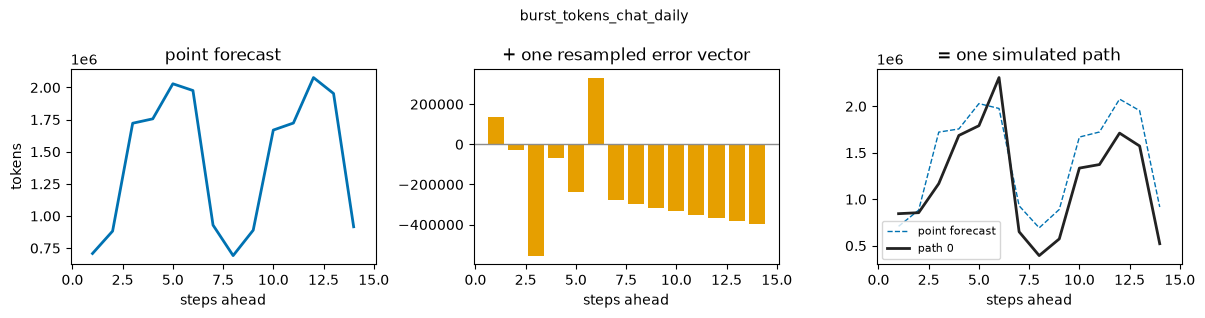

In [9]:
with step("path diagram"):
    import matplotlib.pyplot as plt
    name = "burst_tokens_chat_daily" if "burst_tokens_chat_daily" in NAMES else NAMES[0]
    t = pd.read_parquet(f"outputs/phase3/forecasts/{name}.parquet")
    point = t[t["sample_id"] == -1].sort_values("period_index")["value"].to_numpy()
    path = t[t["sample_id"] == 0].sort_values("period_index")["value"].to_numpy()
    x = range(1, len(point) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharex=True)
    axes[0].plot(x, point, color="#0072B2", lw=2)
    axes[0].set_title("point forecast")
    axes[1].bar(x, path - point, color="#E69F00")
    axes[1].axhline(0, color="#8C8C8C", lw=1)
    axes[1].set_title("+ one resampled error vector")
    axes[2].plot(x, point, color="#0072B2", lw=1, ls="--", label="point forecast")
    axes[2].plot(x, path, color="#222222", lw=2, label="path 0")
    axes[2].set_title("= one simulated path")
    axes[2].legend(fontsize=8)
    for ax in axes:
        ax.set_xlabel("steps ahead")
    axes[0].set_ylabel(t["unit"].iloc[0])
    fig.suptitle(name, fontsize=10)
    plt.tight_layout()
    plt.show()

**Look at the code.** The real simulation function: draw folds with a seeded random generator, extend the
error vectors beyond the backtest horizon, scale them, add them to the point forecast and clip at 0.

In [10]:
with step("code: simulate"):
    show_source("tsaf.simulate", "simulate")
    show_source("tsaf.simulate", "extend_errors")

`tsaf.simulate.simulate`
```python
def simulate(point: np.ndarray, es: ErrorSet, current_level: float, n: int, seed: int,
             growth: str, weights: np.ndarray | None = None) -> Paths:
    """n bootstrap paths around the point forecast (whole-vector resampling, clipped at 0).

    `weights` (optional) are fold sampling probabilities; None = every fold equally likely.
    """
    if es.n_folds == 0:
        raise ValueError("no usable backtest folds to resample")
    point = np.asarray(point, dtype=float)
    rng = np.random.default_rng(seed)
    if weights is None:
        draws = rng.integers(0, es.n_folds, size=n)
    else:
        draws = rng.choice(es.n_folds, size=n, p=np.asarray(weights, dtype=float))
    errs = extend_errors(es.E[draws], len(point), growth)
    scale = float(current_level) if es.relative else 1.0
    raw = point[None, :] + errs * scale
    return Paths(values=np.maximum(raw, 0.0), draws=draws, n_clipped=int((raw < 0).sum()), scale=scale)
```

`tsaf.simulate.extend_errors`
```python
def extend_errors(E_rows: np.ndarray, h: int, growth: str) -> np.ndarray:
    """Error vectors of length h: steps beyond H_cv reuse step H_cv (x sqrt(h/H_cv) if growth == 'sqrt')."""
    n, H = E_rows.shape
    out = np.empty((n, h))
    m = min(h, H)
    out[:, :m] = E_rows[:, :m]
    for j in range(H, h):
        factor = np.sqrt((j + 1) / H) if growth == "sqrt" else 1.0
        out[:, j] = E_rows[:, H - 1] * factor
    return out
```

## 4. Fan charts
How to read them: the dark line is the point forecast; the shaded bands hold 50%, 80% and 95% of the 200
paths; thin grey lines are individual paths. A wide fan means an uncertain series. The title gives the
result of the holdout check (section 5).

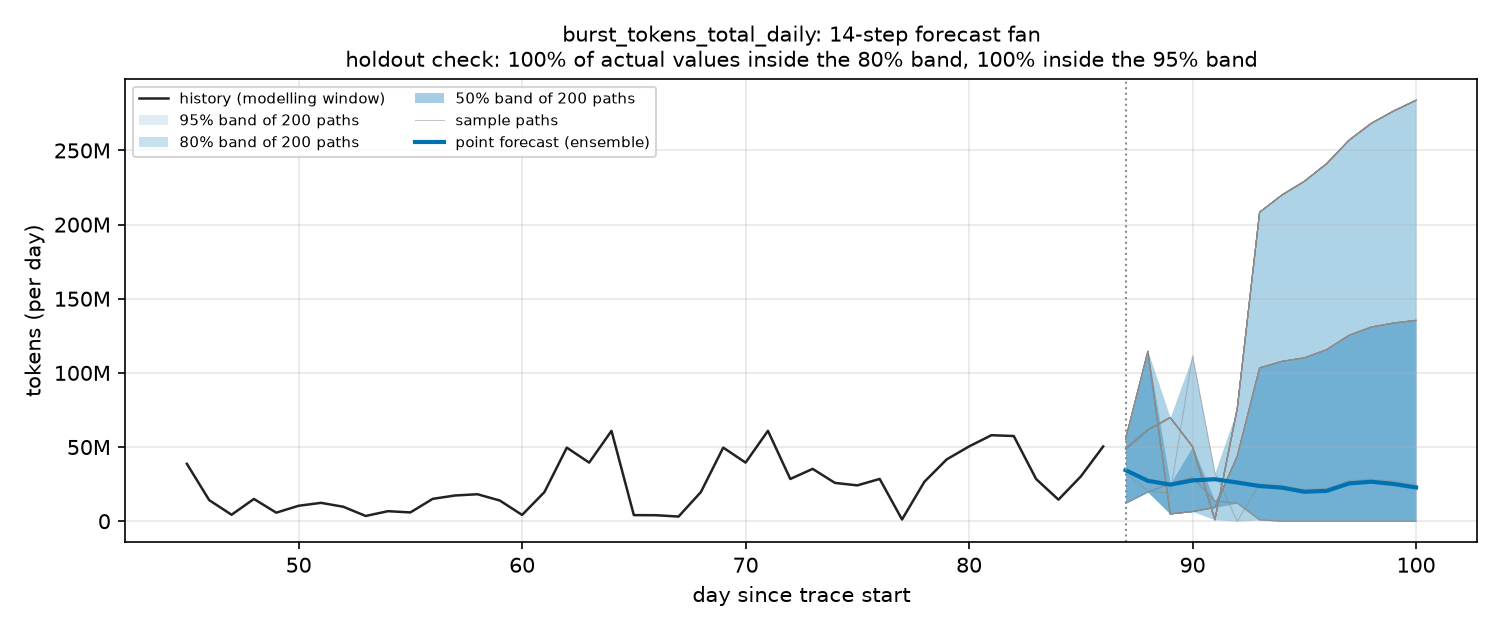

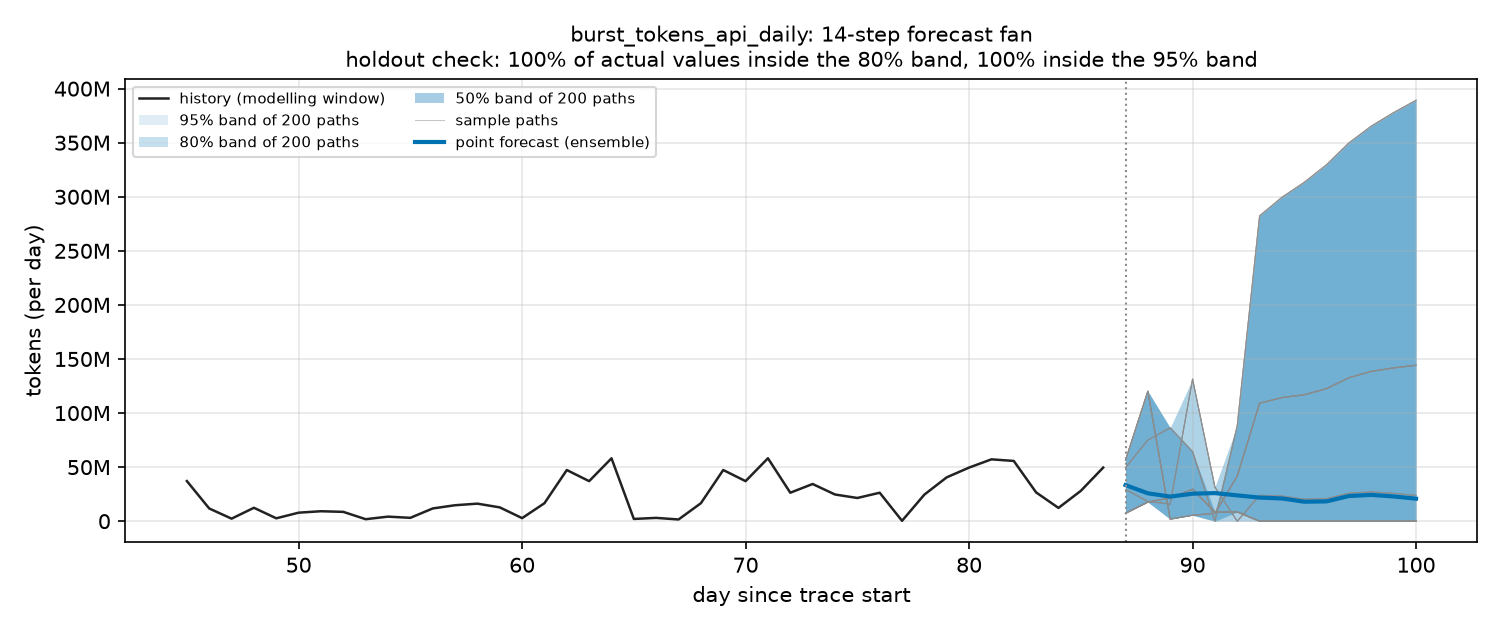

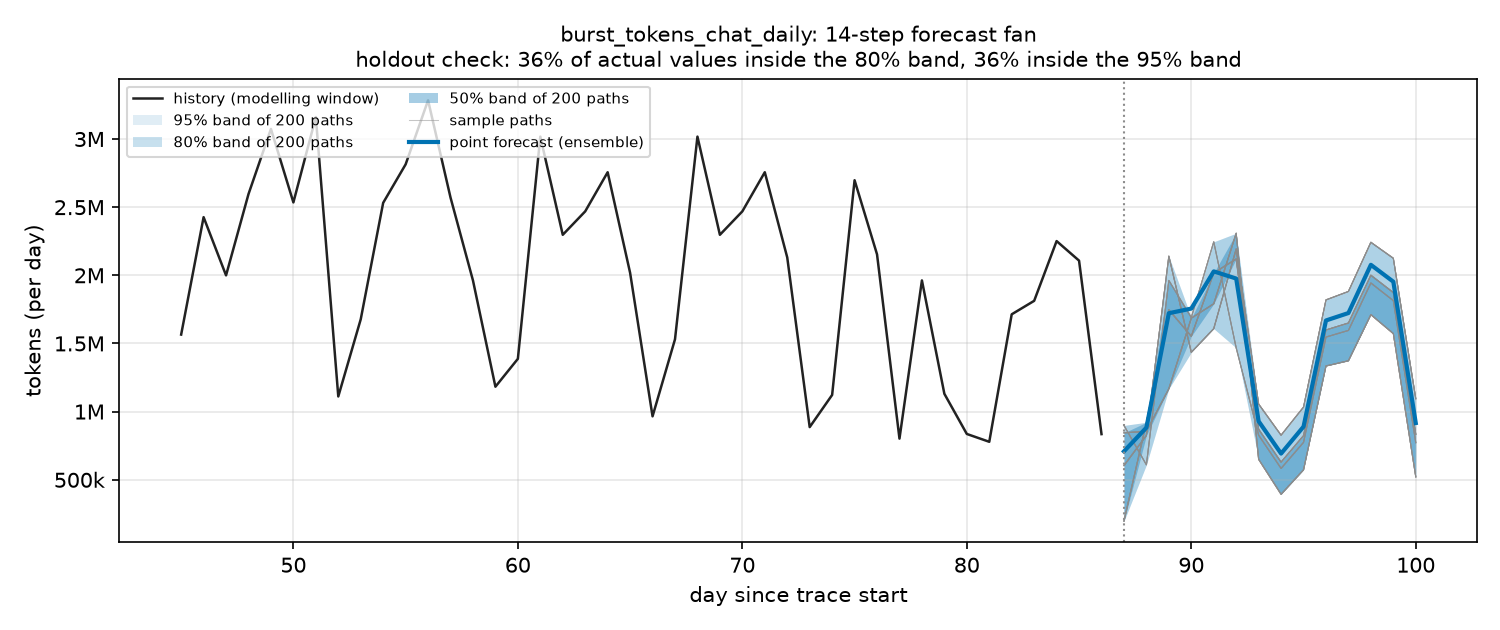

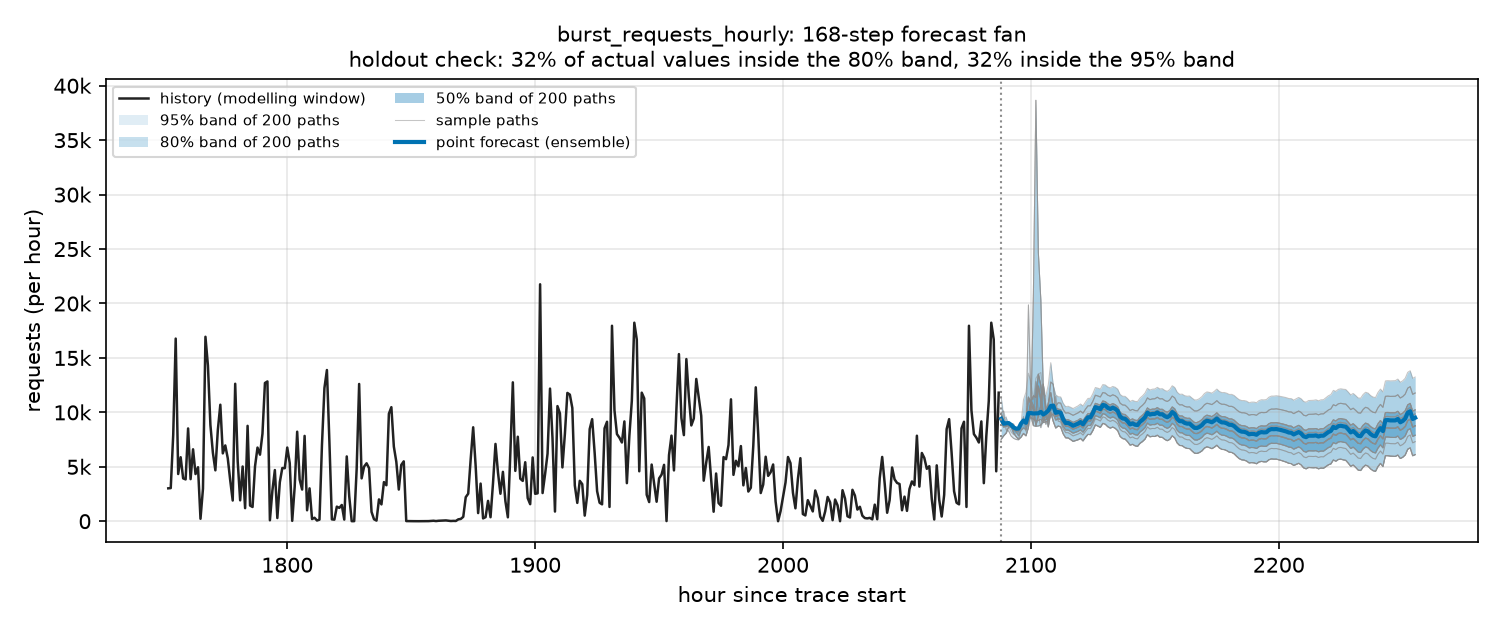

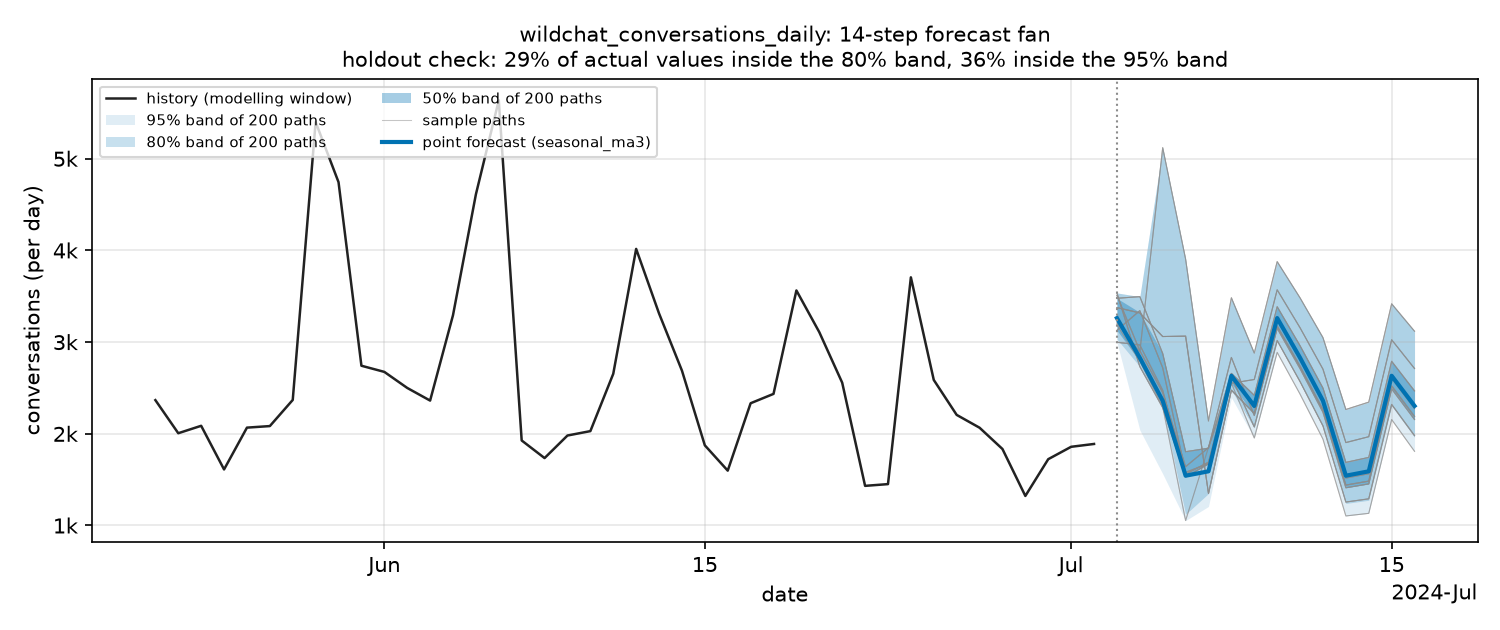

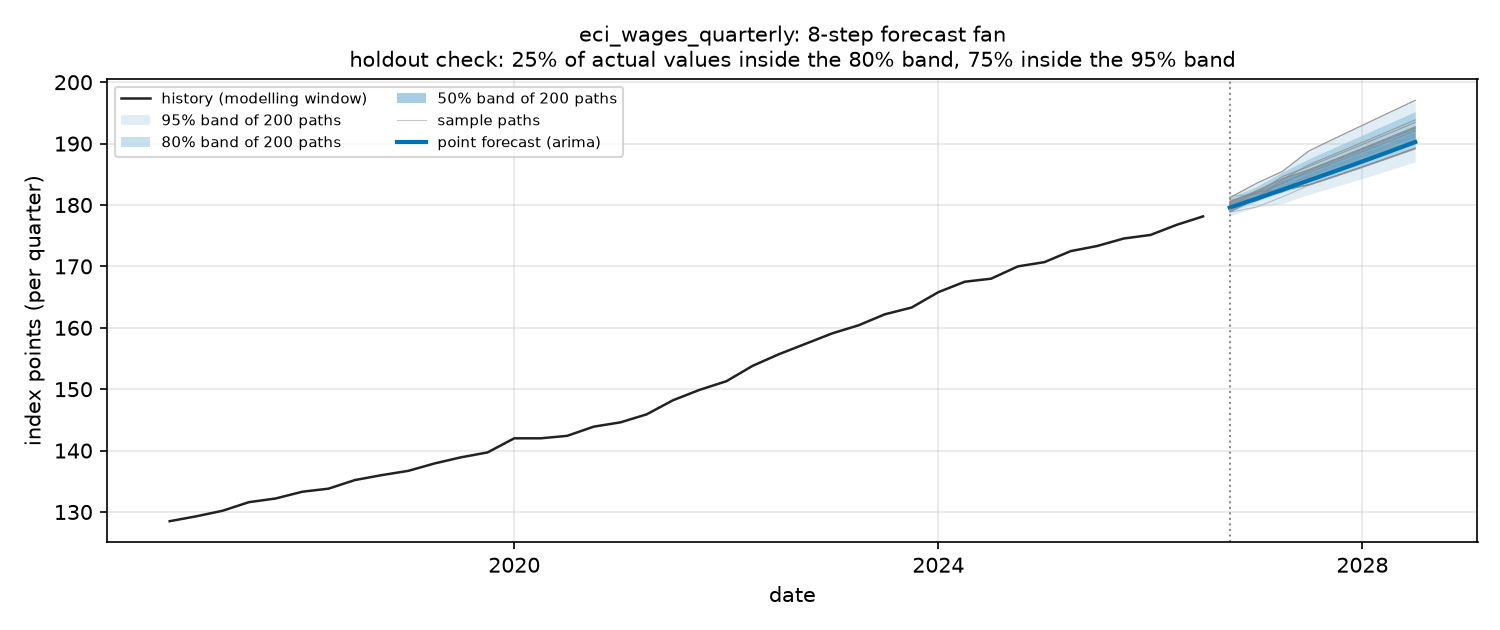

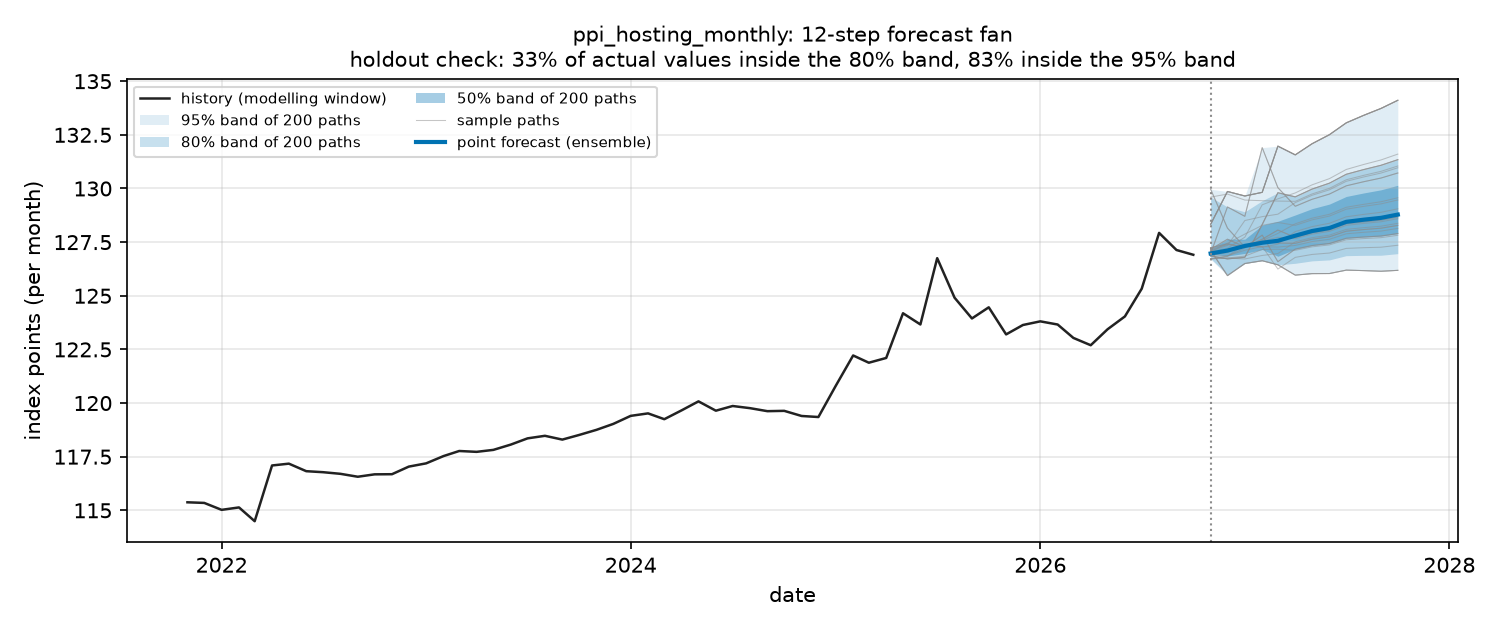

In [11]:
with step("fan charts"):
    for name in NAMES:
        show_img(f"outputs/phase3/figures/fan_{name}.png", width=850)

## 5. Honest check: do the bands hold on data the model has not seen?
We repeat the whole procedure as if we stood at the start of the Phase 2 holdout (refit only on earlier data,
errors only from earlier folds) and count how many actual holdout values fall inside the 80% and 95% bands.
A well calibrated 80% band holds about 80% of them. Rows are flagged when the 80% band holds under 60% or the
95% band under 85%. The hourly series is also split into hours 1 to 24 and 25 to 168.

**Before and after.** Two optional fixes were tried: *recency weights* (newer backtest folds are drawn more
often) and *level matching* (only folds from times with a similar level). For each series they were chosen on
the last backtest folds only (a "pseudo-holdout"), never on this final holdout, then the final check was run
once. The reading below, including the causes of the remaining misses, is taken from the summary file.

,driver,segment,n_holdout_points,coverage_80_before,coverage_80_after,coverage_95_before,coverage_95_after,mean_width_80_before,mean_width_80_after,options,flag
0,burst_tokens_total_daily,all,14,1.000,1.000,1.000,1.000,4.112,4.112,"recency=off, level_match=off",False
1,burst_tokens_api_daily,all,14,1.000,1.000,1.000,1.000,5.668,5.668,"recency=off, level_match=off",False
2,burst_tokens_chat_daily,all,14,0.357,0.357,0.357,0.357,0.371,0.371,"recency=off, level_match=off",True
3,burst_requests_hourly,all,168,0.321,0.321,0.321,0.321,0.809,0.809,"recency=off, level_match=off",True
4,burst_requests_hourly,steps 1-24,24,0.250,0.250,0.250,0.250,0.775,0.775,"recency=off, level_match=off",True
5,burst_requests_hourly,steps 25-168,144,0.333,0.333,0.333,0.333,0.815,0.815,"recency=off, level_match=off",True
6,wildchat_conversations_daily,all,14,0.286,0.286,0.357,0.357,0.645,0.645,"recency=off, level_match=off",True
7,eci_wages_quarterly,all,4,0.250,0.250,0.750,0.750,0.017,0.017,"recency=off, level_match=off",True
8,ppi_hosting_monthly,all,6,0.167,0.333,0.500,0.833,0.014,0.024,"recency=on, level_match=off",True


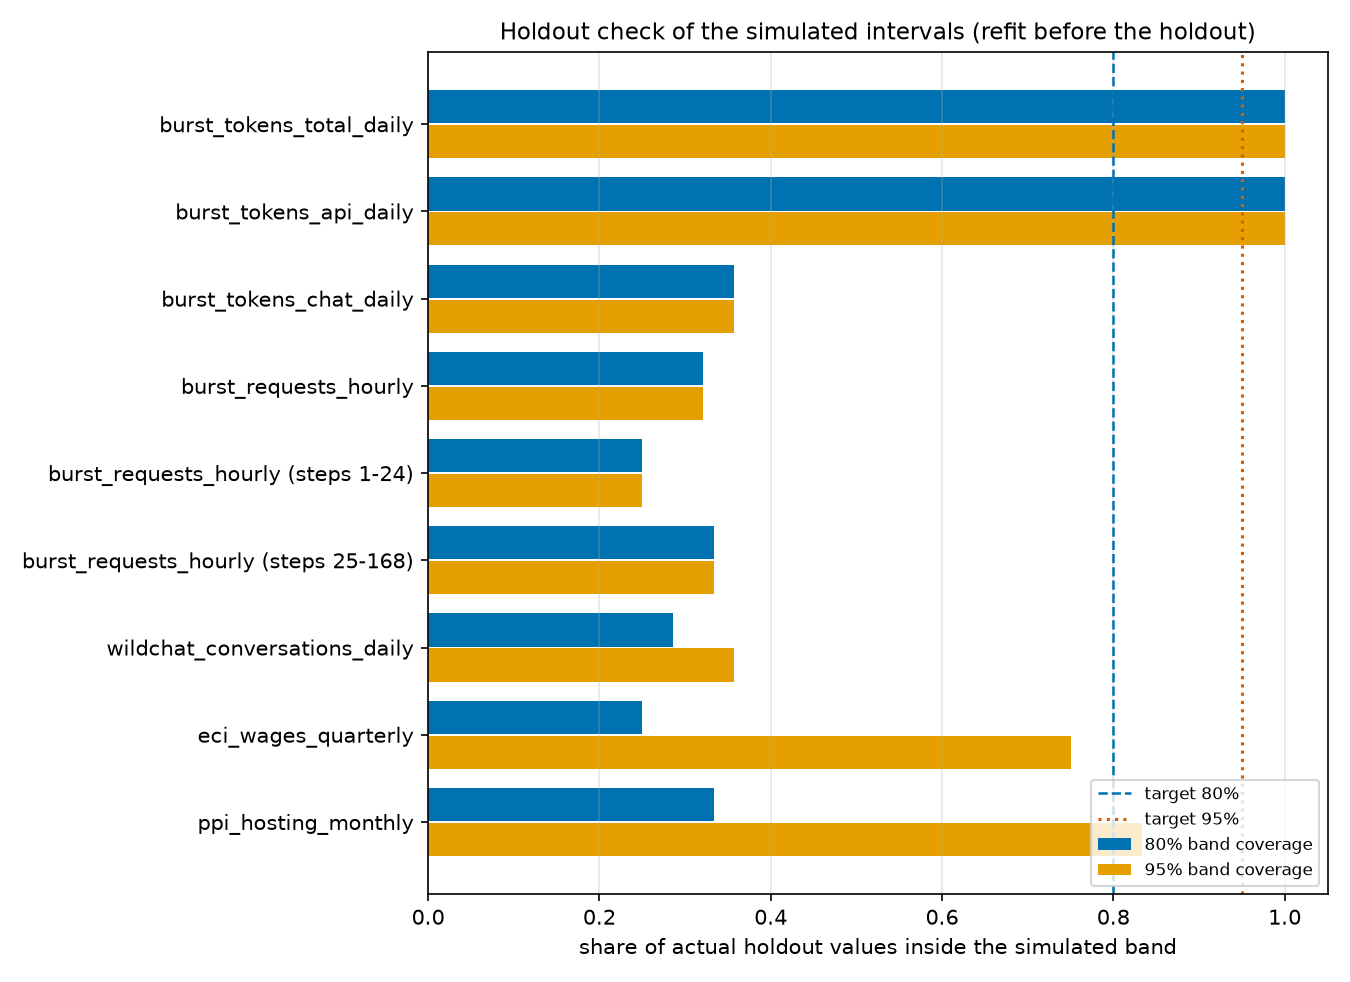

Each driver was refitted on the data before the Phase 2 holdout, its paths were simulated with the same rules (errors only from folds ending before the holdout), and we counted how many actual holdout values fall inside the simulated bands. *Before* = equal fold weights, all folds; *after* = the options chosen per driver in section 4a (never using this holdout). Phase 2's own empirical intervals on the same holdout are shown for comparison.


Width = mean width of the 80% band divided by the current level.

Reading: after the change the bands pass both thresholds (80% coverage at least 60%, 95% at least 85%) for burst_tokens_total_daily, burst_tokens_api_daily and are still too narrow for burst_tokens_chat_daily, burst_requests_hourly, wildchat_conversations_daily, eci_wages_quarterly, ppi_hosting_monthly. The options changed the simulation for ppi_hosting_monthly; for the others the pseudo-holdout found no option closer to 80%.
Calibrated is not the same as useful: for burst_tokens_total_daily (80% band on average 4.1 x the current level), burst_tokens_api_daily (80% band on average 5.7 x the current level) the band is wider than the level itself, because early, quiet folds had large errors relative to their small level and the relative-error rule scales them up to today's level.
Hourly `burst_requests_hourly`: steps 1-24 coverage 25% (80%) / 25% (95%); steps 25-168 33% / 33%.

### Why the remaining drivers miss

- `burst_tokens_chat_daily`: 9 of 14 holdout points fall outside the 80% band (0 above, 9 below); holdout errors are 2.1x the average backtest error (backtest windows: 42 to 69), so the holdout moved much further from the forecast than the backtest windows typically did, with the actual values mostly below the band (holdout mean -30% against the 14 points before it): a level or regime change rather than a sampling problem; the holdout contains the known anomaly at 77, which explains at most one missed point.
- `burst_requests_hourly`: 114 of 168 holdout points fall outside the 80% band (25 above, 89 below); holdout errors are 3.2x the average backtest error (backtest windows: 336 to 863), so the holdout moved much further from the forecast than the backtest windows typically did, with the actual values mostly below the band (holdout mean +18% against the 168 points before it): a level or regime change rather than a sampling problem.
- `wildchat_conversations_daily`: 10 of 14 holdout points fall outside the 80% band (1 above, 9 below); holdout errors are 2.1x the average backtest error (backtest windows: 2024-04-15 to 2024-06-16), so the holdout moved much further from the forecast than the backtest windows typically did, with the actual values mostly below the band (holdout mean -19% against the 14 points before it): a level or regime change rather than a sampling problem.
- `eci_wages_quarterly`: 3 of 4 holdout points fall outside the 80% band (0 above, 3 below); errors are about the backtest size (1.1x) but one-sided: 74% of the backtest errors were positive (actual above forecast) while every holdout miss is below the band, so the band leans the wrong way; with only 4 holdout points each point moves coverage by 25 percentage points.
- `ppi_hosting_monthly`: 4 of 6 holdout points fall outside the 80% band (4 above, 0 below); holdout errors are 4.2x the average backtest error (backtest windows: 2016-07-01 to 2026-03-01), so the holdout moved much further from the forecast than the backtest windows typically did, with the actual values mostly above the band (holdout mean +2% against the 6 points before it): a level or regime change rather than a sampling problem.

- WildChat end check: the last date in the file (2024-07-03) has 936 conversations, 44% of the median of the 28 days before it, so it is partial; the Phase 1 loader already drops it. The two days before it (2024-07-01: 1,858), (2024-07-02: 1,889) are 87%-88% of that median, in line with ordinary weekdays; partial_week flags only 2024-01-15, 2024-07-01 at the series edges. The holdout and the forecasts are therefore not affected by undercounting.

### 4a. How the options were chosen (pseudo-holdout, never the final holdout)

Two switchable options (src/config.py): **recency weights** (a fold's chance of being drawn halves every 0.25 x n_folds folds of age) and **level matching** (positive series only use folds whose level is within 0.5x-2x of the current level; if fewer than 3 qualify, the closest 3). For each driver the last 20% of the backtest folds (at least 2) were held out and simulated from the earlier folds only, using each fold's stored out-of-sample forecast. The combination with 80% coverage closest to 0.8 was chosen (tie: the narrower band; identical results keep the options off).


For burst_tokens_total_daily, burst_tokens_api_daily, burst_tokens_chat_daily all four combinations give the same result: with so few training folds the bands are the smallest and largest fold error either way, and every fold level was within the matching band (or there were fewer folds than the matching minimum).

In [12]:
with step("interval check"):
    ic = read_table("phase3", "interval_check")
    show_table(ic, n=20, cols=["driver", "segment", "n_holdout_points", "coverage_80_before", "coverage_80_after",
                               "coverage_95_before", "coverage_95_after", "mean_width_80_before",
                               "mean_width_80_after", "options", "flag"])
    show_img("outputs/phase3/figures/interval_check.png", width=750)
    text = md_section("outputs/phase3/PHASE3_SUMMARY.md", "Honest check")
    if text:
        display(Markdown("\n".join(l for l in text.splitlines() if not l.startswith("|"))))

**How the options were chosen.** Each row is one option combination scored on the held-out backtest folds;
the chosen one has 80% coverage closest to 0.8 (tie: the narrower band). Identical rows mean the option made
no difference for that series, so it stays off.

In [13]:
with step("interval tuning"):
    tun = read_table("phase3", "interval_tuning")
    show_table(tun, n=40, cols=["driver", "option", "n_heldout_folds", "coverage_80", "coverage_95",
                                "mean_width_80_relative_to_level", "chosen"])

,driver,option,n_heldout_folds,coverage_80,coverage_95,mean_width_80_relative_to_level,chosen
0,burst_tokens_total_daily,"recency=off, level_match=off",2,0.071,0.071,0.573,True
1,burst_tokens_total_daily,"recency=off, level_match=on",2,0.071,0.071,0.573,False
2,burst_tokens_total_daily,"recency=on, level_match=off",2,0.071,0.071,0.573,False
3,burst_tokens_total_daily,"recency=on, level_match=on",2,0.071,0.071,0.573,False
4,burst_tokens_api_daily,"recency=off, level_match=off",2,0.071,0.071,0.682,True
5,burst_tokens_api_daily,"recency=off, level_match=on",2,0.071,0.071,0.682,False
6,burst_tokens_api_daily,"recency=on, level_match=off",2,0.071,0.071,0.682,False
7,burst_tokens_api_daily,"recency=on, level_match=on",2,0.071,0.071,0.682,False
8,burst_tokens_chat_daily,"recency=off, level_match=off",2,0.500,0.500,0.245,True
9,burst_tokens_chat_daily,"recency=off, level_match=on",2,0.500,0.500,0.245,False


## 6. BurstGPT 30-day run-rate
Phase 4 works in months, but BurstGPT is forecast for 14 days. The run-rate of each path is the sum of its
14 simulated days plus 16 times the mean of its last 7 days. **The last 16 days are extrapolated, not forecast.**

,driver,p10 (M tokens),p50 (M tokens),p90 (M tokens),point_forecast (M tokens),extrapolated_days
0,burst_tokens_total_daily,113.2,3160.0,6350.6,727.1,16
1,burst_tokens_api_daily,93.2,3335.6,8613.3,667.7,16
2,burst_tokens_chat_daily,33.9,39.9,46.1,42.6,16


**Warning: the last 16 of the 30 days are extrapolated from the last 7 simulated days.**

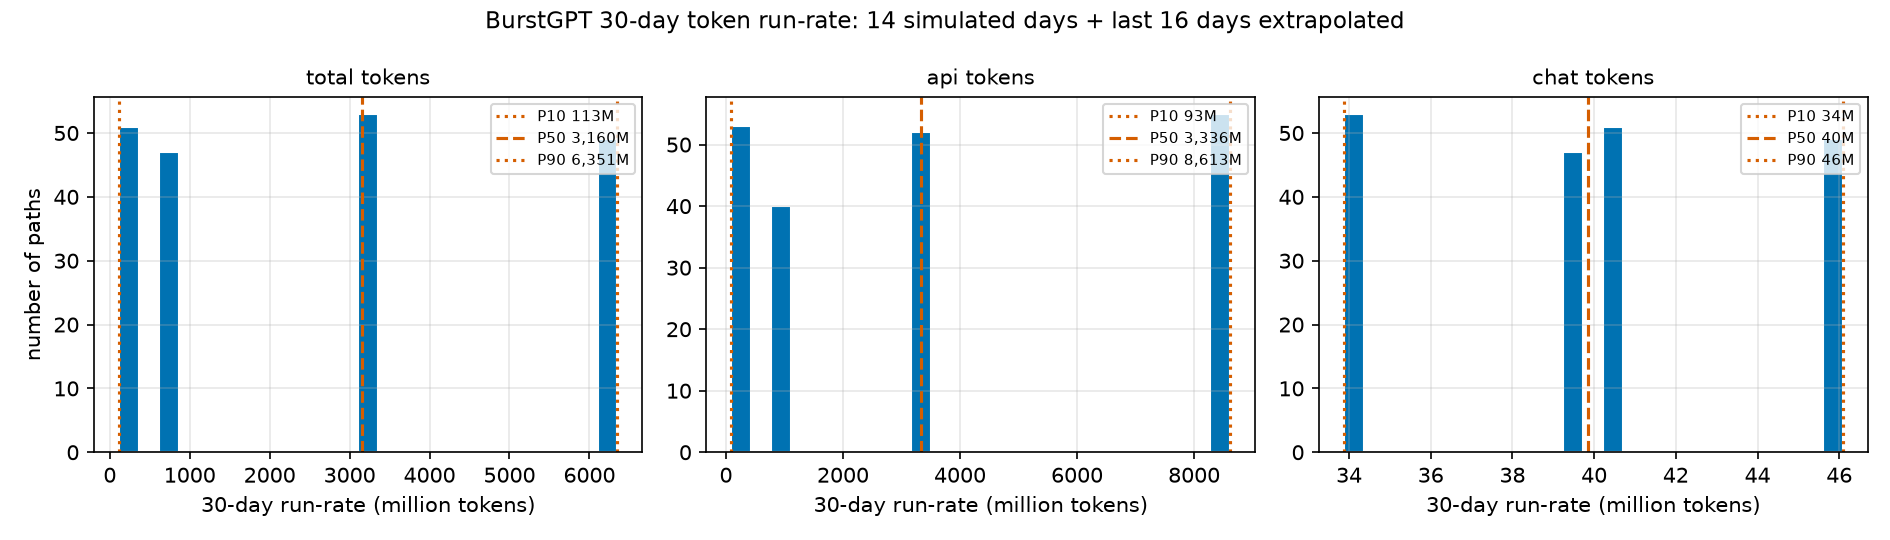

In [14]:
with step("run-rate"):
    s = pd.read_csv("outputs/phase3/forecasts/burstgpt_monthly_run_rate_summary.csv")
    for c in ("p10", "p50", "p90", "point_forecast"):
        s[c + " (M tokens)"] = s[c] / 1e6
    show_table(s, cols=["driver", "p10 (M tokens)", "p50 (M tokens)", "p90 (M tokens)",
                        "point_forecast (M tokens)", "extrapolated_days"], digits=1)
    display(Markdown("**Warning: the last 16 of the 30 days are extrapolated from the last 7 simulated days.**"))
    show_img("outputs/phase3/figures/run_rate_burstgpt.png", width=850)

## 7. Scenario inputs: assumptions, not forecasts
The time-saved scenarios are not forecast; they are taken directly from the data and kept in a separate file
(`kind = assumption`). Each row says where its number comes from (`source`) and exactly how it was taken
(`derivation`). Rows whose meaning was unclear would be marked `needs_review`.

,scenario,parameter,value,unit,status,source,derivation
0,downside,task_time_change_with_ai,18.800,pct_change_in_task_time,from_quality_log,"METR RCT (paper estimate, recorded in reports/data_quality.md)",Read from the quality log line 'paper_estimate: +18.8% time with AI (95% CI ~+1% to +3...
1,downside,task_time_change_with_ai_naive,31.508,pct_change_in_task_time,measured,METR RCT (metr_effect_summary),"Mean minutes per task with AI allowed (119.54, 136 tasks) divided by without AI (90.90..."
2,expected,time_saved_share_of_work_hours,2.084,pct_of_work_hours,measured,FRED GenAI tracker RPSGENAITSALL (genai_tracker),"Latest quarter (2026-07-01) of time_saved_pct_hours, GenAI time savings as % of work h..."
3,optimistic,time_saved_share_of_work_hours,3.908,pct_of_work_hours,measured,FRED GenAI tracker panel RPSGENAITSIND5 (genai_timesaved_panel),Highest value in the 8-series occupation/industry panel: 'GenAI time savings: wholesal...


Rows marked needs_review: 0


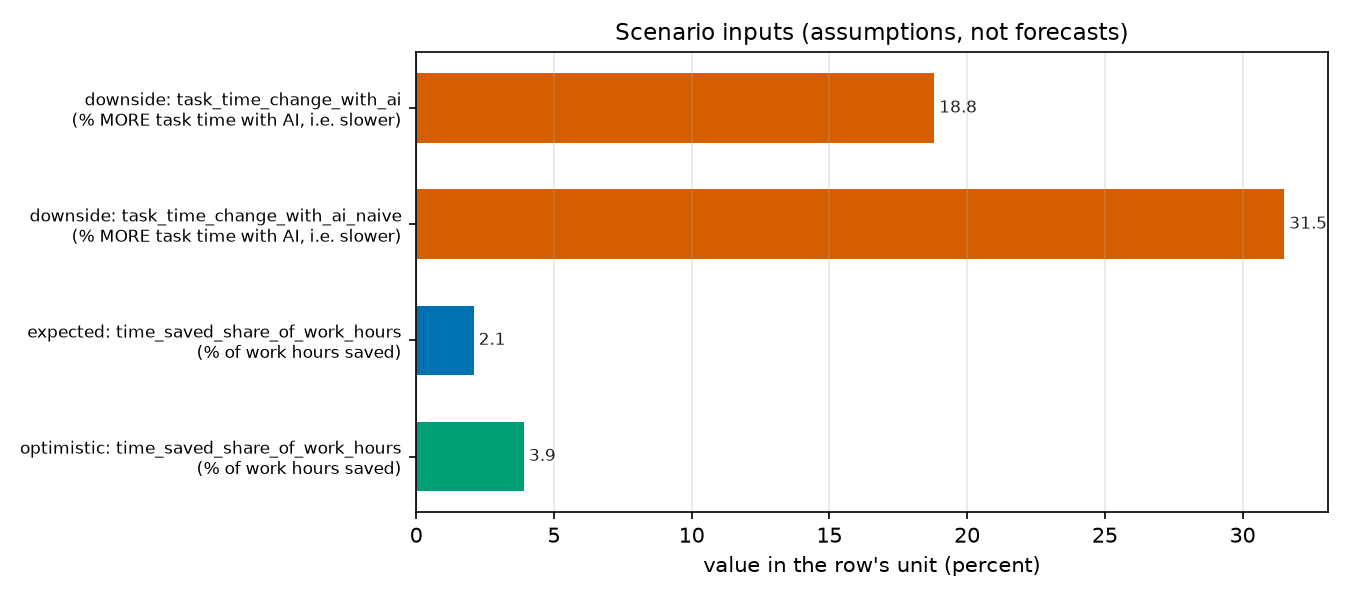

In [15]:
with step("scenarios"):
    sc = pd.read_csv("outputs/phase3/forecasts/scenario_tables.csv")
    show_table(sc, n=20, cols=["scenario", "parameter", "value", "unit", "status", "source", "derivation"])
    nr = sc[sc["status"] == "needs_review"]
    print(f"Rows marked needs_review: {len(nr)}" + (": " + ", ".join(nr["parameter"]) if len(nr) else ""))
    show_img("outputs/phase3/figures/scenarios.png", width=750)

## 8. Validation
Every forecast file is checked: the ten columns in the right order, no missing or negative values,
exactly 200 paths plus the point forecast, the full horizon, no duplicate rows. PASS means Phase 4 can read it.

In [16]:
with step("validation"):
    show_table(read_table("phase3", "validation"), n=20)

,file,status,problems
0,burst_tokens_total_daily.parquet,PASS,NaN
1,burst_tokens_api_daily.parquet,PASS,NaN
2,burst_tokens_chat_daily.parquet,PASS,NaN
3,burst_requests_hourly.parquet,PASS,NaN
4,wildchat_conversations_daily.parquet,PASS,NaN
5,eci_wages_quarterly.parquet,PASS,NaN
6,ppi_hosting_monthly.parquet,PASS,NaN
7,scenario_tables.csv,PASS,NaN


## 9. Explore a series (optional, interactive)
Pick a series to see its fan chart and the first rows of its table. Nothing else depends on this cell.

In [17]:
with step("explorer"):
    try:
        import ipywidgets as widgets
    except ImportError:
        widgets = None
        print("ipywidgets is not available; the fan charts above show the same content.")
    if widgets is not None and NAMES:
        box = widgets.Output()
        dd = widgets.Dropdown(options=NAMES, value=NAMES[0], description="series")
        def _show(change=None):
            box.clear_output()
            with box:
                show_img(f"outputs/phase3/figures/fan_{dd.value}.png", width=800)
                show_table(pd.read_parquet(f"outputs/phase3/forecasts/{dd.value}.parquet"), n=5, digits=1)
        dd.observe(_show, names="value")
        display(dd, box)
        _show()

Dropdown(description='series', options=('burst_tokens_total_daily', 'burst_tokens_api_daily', 'burst_tokens_ch…

Output()

# Summary

The talking points and limitations below are taken directly from `PHASE3_SUMMARY.md`,
so every number comes from the run.

In [18]:
with step("summary"):
    for title in ("What to say in the review", "Limitations"):
        text = md_section("outputs/phase3/PHASE3_SUMMARY.md", title)
        display(Markdown(f"### Phase 3: {title}\n\n" + (text or "_Section not found._")))

### Phase 3: What to say in the review

Phase 3 turns the chosen model of each of the 7 drivers into 200 simulated future paths plus a point forecast, all written in one ten-column table format. Every chosen model refitted cleanly on the full window. Paths are built by resampling whole vectors of out-of-sample backtest errors, scaled to the current level for the 6 strictly positive series. On the Phase 2 holdout the simulated 80% band covered between 25% and 100% of the actual values; 2 of 7 drivers pass both coverage thresholds. Recency weights and level matching were tested on the last backtest folds only; ppi_hosting_monthly moved from 17% to 33% (80%) and 50% to 83% (95%). For hourly requests the 80% band covered 25% of hours 1 to 24 and 33% of the later hours. The 30-day run-rate of burst_tokens_total_daily has P10 113M, P50 3,160M and P90 6,351M tokens, with the last 16 days extrapolated. Input tokens are 86% of all BurstGPT tokens in the window. The scenario table holds 4 assumption rows taken directly from the METR and FRED tracker data; they are kept apart from the forecasts. Reruns give identical files because every driver has a fixed seed.

### Phase 3: Limitations

- Short window: BurstGPT has 87 clean days; burst_tokens_total_daily, burst_tokens_api_daily, burst_tokens_chat_daily have fewer than 5 backtest folds to resample from.
- BurstGPT has no calendar dates; periods are days or hours after day 86 and the weekend is inferred.
- For dated sources (WildChat, ECI, PPI) `calendar_month` is the month after the data end, which can lie in the past relative to today.
- The bootstrap assumes future errors look like past backtest errors; a regime change is not covered.
- Whole-vector resampling can only reuse the folds that exist: with k folds each step has at most k distinct path values, so the 80% and 95% bands are close to the smallest and largest fold error and often nearly coincide.
- The `sqrt` growth beyond the backtest horizon is an assumption, not an estimate.
- Series with zeros (hourly requests) use absolute errors from early, quieter folds, so their bands can be too narrow when volume is higher; the holdout check measures this.

In [19]:
with step("what we have"):
    display(Markdown("### What we have so far"))
    display(pd.DataFrame([{"phase": "1. exploration and baselines", "built": "loaders, decomposition, trend methods, ADF/KPSS, ACF/PACF, anomaly screen, 5 baselines, backtest", "outputs": "outputs/phase1: tables, figures, handoff.json, PHASE1_SUMMARY.md", "notebook": "TSAF_Phase1.ipynb"}, {"phase": "2. forecasting models and rolling backtests", "built": "smoothing, ARIMA/SARIMA/SARIMAX, Ridge/RF/XGBoost, ensemble, intervals, diagnostics, model choice", "outputs": "outputs/phase2: tables, figures, chosen_models.json, cv_residuals.parquet, PHASE2_SUMMARY.md", "notebook": "TSAF_Phase2.ipynb"}, {"phase": "3. simulated paths and the standard forecast table", "built": "refit of the chosen models, 200 bootstrap paths per driver, holdout interval check, standard table, scenarios", "outputs": "outputs/phase3: forecasts/*.parquet and .csv, manifest.json, inputs_for_phase4.json, PHASE3_SUMMARY.md", "notebook": "TSAF_Phase3.ipynb"}]))

### What we have so far

,phase,built,outputs,notebook
0,1. exploration and baselines,"loaders, decomposition, trend methods, ADF/KPSS, ACF/PACF, anomaly screen, 5 baselines...","outputs/phase1: tables, figures, handoff.json, PHASE1_SUMMARY.md",TSAF_Phase1.ipynb
1,2. forecasting models and rolling backtests,"smoothing, ARIMA/SARIMA/SARIMAX, Ridge/RF/XGBoost, ensemble, intervals, diagnostics, m...","outputs/phase2: tables, figures, chosen_models.json, cv_residuals.parquet, PHASE2_SUMM...",TSAF_Phase2.ipynb
2,3. simulated paths and the standard forecast table,"refit of the chosen models, 200 bootstrap paths per driver, holdout interval check, st...","outputs/phase3: forecasts/*.parquet and .csv, manifest.json, inputs_for_phase4.json, P...",TSAF_Phase3.ipynb


**Next: Phase 4**, the Monte Carlo cost and value engine, will read the standard forecast tables, `inputs_for_phase4.json` and the scenario table. Then Phase 5 (dashboard) and Phase 6 (report).